# Week 7 group project: Object Recognition
AI for Good - Minor ADSAI

[Open this notebook in Google Colab](https://colab.research.google.com/github/BTuyn/AI4G/blob/main/Week%207/Week7_Starter_Object_Recognition.ipynb)

**Your group's mission:** build a very simple app (an MVP) that does
**object recognition: finding objects in a photo, with a box and a label** on photos you take yourselves, in or outside the school, find out how
good it is, and teach the rest of the class about it.

*Question for your group: what is in the photo, where is it, and how many are there?*

**Timeline**

| Time | What |
|------|------|
| 10:45-11:30 | **Phase 1 (45 min):** take photos and come up with your MVP - no laptops needed (read sections 1 and 3 for ideas) |
| 11:30 | **Stand-up:** 3 minutes per group - your MVP idea, your photos, who does what |
| 12:00-14:30 | **Phase 2:** photos into Colab, build the MVP and make it work, ground truth, evaluation, presentation (sections 0-8) |
| 14:45-15:30 | **Presentations:** your MVP, 10 minutes per group + 3 minutes questions |

**Your presentation must explain**

1. **What the technique is** - what goes in, what comes out, what it is used for (section 1)
2. **What data processing is needed** - from a phone photo to something the model can use, and the ground truth (sections 4 and 6)
3. **What you did** - your idea, your photos, how you built your MVP (sections 3 and 5)
4. **How you evaluate it** - which metric, why, and your result (section 7)
5. **The end result: your MVP** - show it working, and where it fails (section 8)

**Organise your group.** You are a big group, so split the work. A split
that works: a **photo team** (collects photos, makes the ground truth), a
**build team** (runs this notebook, builds the MVP), an **evaluation team**
(chooses and calculates the metric), and a **presentation team** (slides,
demo, timing). Pick one person who keeps an eye on the clock. Share this
notebook through Google Drive so everybody can see it.

## 0. Setup - run these cells once

The first cell is only needed for iPhone photos in HEIC format (or set the
iPhone camera to *Settings -> Camera -> Formats -> Most Compatible*). The
second cell loads the tools and some helpers:

- `upload_to("photos")` - choose photos on your laptop; they land in the folder `photos`
- `take_photo("photos", "name.jpg")` - take a photo with the laptop camera
- `load_folder("photos")` - load all photos of a folder: turned the right way up and made smaller
- `show([...])` - show pictures next to each other
- `save_result(name)` - save the picture you just made in the folder `results`, for your slides
- `download_results()` - download the folder `results` as a zip

In [1]:
# Only needed for iPhone HEIC photos
!pip install -q pillow-heif


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\milou\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:
# Run, do not read
import warnings
warnings.filterwarnings("ignore")
import os, glob, base64, shutil, urllib.request, zipfile
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageOps
import torch
import torchvision.transforms.functional as TF
torch.set_grad_enabled(False)
try:
    import pillow_heif
    pillow_heif.register_heif_opener()
except ImportError:
    pass
os.makedirs("results", exist_ok=True)

def show(images, titles=None, size=3.5):
    if not isinstance(images, list):
        images = [images]
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    if len(images) == 1:
        axes = [axes]
    for k in range(len(images)):
        axes[k].imshow(images[k], cmap="gray" if images[k].ndim == 2 else None)
        axes[k].axis("off")
        if titles:
            axes[k].set_title(titles[k], fontsize=9)
    plt.show()

def save_result(name):
    # call this INSIDE the same cell, right after a picture is drawn
    plt.savefig(os.path.join("results", name), dpi=120, bbox_inches="tight")
    print("saved results/" + name)

def download_results():
    from google.colab import files
    shutil.make_archive("results", "zip", "results")
    files.download("results.zip")

def upload_to(folder):
    from google.colab import files
    os.makedirs(folder, exist_ok=True)
    for name, content in files.upload().items():
        with open(os.path.join(folder, name), "wb") as f:
            f.write(content)

def take_photo(folder, name):
    from IPython.display import display, Javascript
    from google.colab.output import eval_js
    os.makedirs(folder, exist_ok=True)
    display(Javascript('''
    async function takePhoto() {
      const div = document.createElement('div');
      const button = document.createElement('button');
      button.textContent = 'Capture';
      div.appendChild(button);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => button.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', 0.9);
    }'''))
    data_url = eval_js("takePhoto()")
    with open(os.path.join(folder, name), "wb") as f:
        f.write(base64.b64decode(data_url.split(",")[1]))
    print("saved", os.path.join(folder, name))

def load_folder(folder, max_size=1024):
    photos = {}
    for f in sorted(glob.glob(os.path.join(folder, "*"))):
        if "_mask" in os.path.basename(f):
            continue
        try:
            im = ImageOps.exif_transpose(Image.open(f)).convert("RGB")
        except Exception:
            print("skipped (not a photo):", f)
            continue
        im.thumbnail((max_size, max_size))
        photos[os.path.basename(f)] = np.array(im)
    print(folder, ":", len(photos), "photos")
    return photos

def download_examples(folder, urls):
    os.makedirs(folder, exist_ok=True)
    for url in urls:
        target = os.path.join(folder, url.split("/")[-1])
        if not os.path.exists(target):
            urllib.request.urlretrieve(url, target)

print("Ready")

Ready


## 1. What is object recognition?

- **Classification** gives one label for the whole photo: "this is a bicycle".
- **Object detection** finds *every* object, with a **box**, a **label** and a
  **confidence** (how sure the model is, from 0 to 1). Because you know where
  each object is, you can **count**.

You have two pre-trained detectors (run the cell; it downloads them once):

| Model | What it can find | How you ask |
|-------|------------------|-------------|
| **Mask R-CNN** (trained on COCO) | 80 fixed kinds: person, bicycle, car, chair, laptop, cup, bottle, bench, dog, ... | `find(photo, ["person", "chair"])` |
| **OWLv2** (by Google) | anything you describe in words | `find(photo, ["trash bin", "bike"], model="text")` |

The **threshold** decides which boxes you keep: low = more found, more
mistakes; high = surer, but more missed.

Object recognition is an AI technique that identifies objects in photos.

Object classification predicts what is in a photo, while object detection also shows where objects are located by drawing boxes around them.

Each detected object gets a label and a confidence score. This makes it possible to count objects, such as people and chairs.

This technique can be useful for checking how busy a classroom or study area is.

In [3]:
# Run, do not read: two pre-trained detectors
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from transformers import pipeline
coco_weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
coco_model = maskrcnn_resnet50_fpn(weights=coco_weights).eval()
COCO = [name for name in coco_weights.meta["categories"]]
text_model = pipeline("zero-shot-object-detection", model="google/owlv2-base-patch16-ensemble")

def find(picture, what, threshold=0.5, model="coco", draw=True, title=""):
    boxes = []                                    # (label, score, [x1, y1, x2, y2])
    if model == "coco":
        out = coco_model([TF.to_tensor(picture)])[0]
        for box, lab, score in zip(out["boxes"], out["labels"], out["scores"]):
            if COCO[int(lab)] in what and score >= threshold:
                boxes.append((COCO[int(lab)], float(score), box.tolist()))
    else:
        for r in text_model(Image.fromarray(picture), candidate_labels=what, threshold=threshold):
            b = r["box"]
            boxes.append((r["label"], float(r["score"]), [b["xmin"], b["ymin"], b["xmax"], b["ymax"]]))
    if draw:
        fig, ax = plt.subplots(figsize=(7, 5))
        ax.imshow(picture)
        for label, score, (x1, y1, x2, y2) in boxes:
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="yellow", linewidth=2))
            ax.text(x1, y1, label + " " + str(round(score, 2)), fontsize=7, backgroundcolor="yellow")
        ax.axis("off")
        ax.set_title(title)
    return boxes

def counts(boxes, what):
    result = {}
    for w in what:
        result[w] = sum(1 for b in boxes if b[0] == w)
    return result

print("COCO knows:", [n for n in COCO if n not in ("__background__", "N/A")])

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to C:\Users\milou/.cache\torch\hub\checkpoints\maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:12<00:00, 14.2MB/s] 
Loading weights: 100%|██████████| 418/418 [00:00<00:00, 614.51it/s]


COCO knows: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush']


## 2. Try it now

One example photo, both models. This is already a tiny MVP: a photo in, boxes
and counts out.

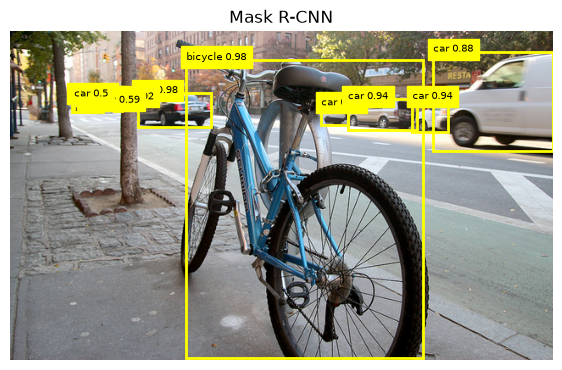

{'car': 11, 'bicycle': 1}


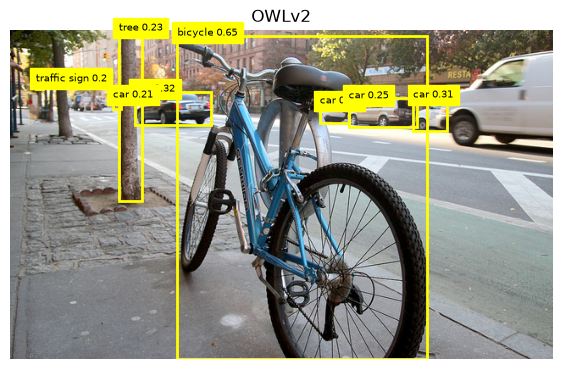

{'car': 5, 'bicycle': 1, 'tree': 1, 'traffic sign': 1}


In [4]:
street = np.array(Image.open(urllib.request.urlopen("http://images.cocodataset.org/val2017/000000174482.jpg")).convert("RGB"))
boxes = find(street, ["car", "bicycle"], 0.5, title="Mask R-CNN")
plt.show()
print(counts(boxes, ["car", "bicycle"]))
boxes = find(street, ["car", "bicycle", "tree", "traffic sign"], 0.2, model="text", title="OWLv2")
plt.show()
print(counts(boxes, ["car", "bicycle", "tree", "traffic sign"]))

## 3. Your photos

**Ideas** (or think of your own):

- *Free seats:* count chairs and people in the study area or the canteen
- *Bike shed:* how many bicycles are parked, and is it full?
- *Litter patrol:* count bottles, cans or cups left on the tables or outside
- *Green campus:* how many trees and plants are around the building?
- *Lending desk:* how many laptops are in use in a classroom?

Decide **what** your app counts, and **for whom**. Then go and take photos.

**Rules for taking photos**

- **People only with permission.** Only photograph people who say yes - accept
  a no. Other people in the school must not be recognisable: aim away, or
  photograph them from behind.
- **Never put photos of people online.** Not in your portfolio (it is public)
  and not in a shared folder outside the group. Before you upload this notebook
  anywhere: *Edit -> Clear all outputs*. Delete the photos after this week.
- **Make it hard for the model.** Different places, light, distances and
  angles, and a few difficult photos (crowded, dark, half hidden). A test with
  only easy photos tells you nothing.
- **Enough photos:** at least 10, more is better. Any phone photo works.

**Getting your photos into Colab:** `upload_to("photos")` from the laptop
(send them from your phone by AirDrop, e-mail or Google Drive first), drag a
zip into the file panel on the left and run `!unzip -q yourfile.zip -d photos`,
or use the laptop camera with `take_photo("photos", "name.jpg")`.

photos : 16 photos


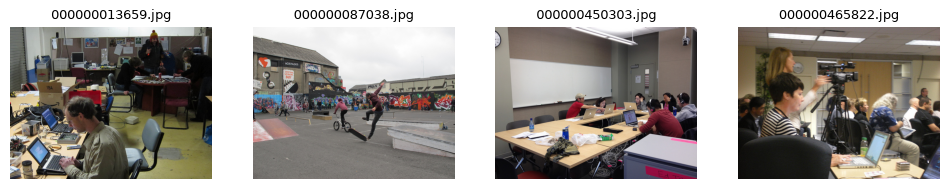

In [5]:
# upload_to("photos")                         # or a zip, or take_photo(...)
folder = "photos"
what = ["person", "chair"]                      # the objects your app finds
model = "coco"                                  # "coco" for the 80 COCO objects, "text" for anything else

# No photos yet? These 4 example photos let you test everything first.
# Delete these two lines once your own photos are in the folder "photos".
download_examples("photos", ["http://images.cocodataset.org/val2017/" + n for n in
                             ["000000087038.jpg", "000000450303.jpg", "000000465822.jpg", "000000013659.jpg"]])

photos = load_folder(folder)
show([photos[n] for n in photos][:4], list(photos)[:4], size=3)

## 4. Data processing

A phone photo is not ready for a model. Run the cell: it shows what happens to
one of your photos on its way in. **Use this for part 2 of your
presentation.**

1. the file from the phone:      640 x 480 pixels, RGB
2. turned the right way up:      no rotation needed (phones store the rotation separately, in the EXIF data)
3. made smaller (max 1024):      640 x 480 pixels
4. a grid of numbers:            (480, 640, 3) = 921600 numbers from 0 to 255
5. scaled to 0-1 for the model:  0.0 to 1.0


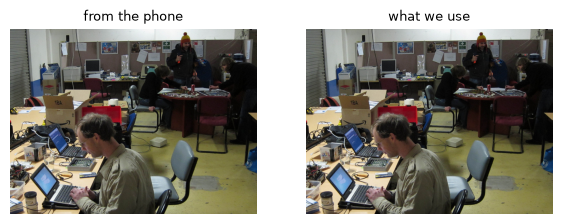

In [7]:
# Run, do not read: what happens to a phone photo before the model sees it
name = list(photos)[0]
original = Image.open(glob.glob(os.path.join(folder, name))[0])
print("1. the file from the phone:     ", original.size[0], "x", original.size[1], "pixels,", original.mode)
upright = ImageOps.exif_transpose(original)
print("2. turned the right way up:     ", "yes" if upright.size != original.size else "no rotation needed",
      "(phones store the rotation separately, in the EXIF data)")
print("3. made smaller (max 1024):     ", photos[name].shape[1], "x", photos[name].shape[0], "pixels")
print("4. a grid of numbers:           ", photos[name].shape, "=", photos[name].size, "numbers from 0 to 255")
x = TF.to_tensor(photos[name])
print("5. scaled to 0-1 for the model: ", round(float(x.min()), 2), "to", round(float(x.max()), 2))
show([np.array(original.convert("RGB")), photos[name]], ["from the phone", "what we use"])

**For object recognition, the ground truth is a count per photo** (section 6):
you count the objects yourself, before you look at the model. For a full
evaluation you also judge every box the model draws: right or wrong.

## 5. Your MVP

An MVP is the smallest thing that is useful: a photo in, an answer out. Change
`my_app` so it answers **your** question in a sentence, then run it on all
your photos. Try a few thresholds first and pick one.

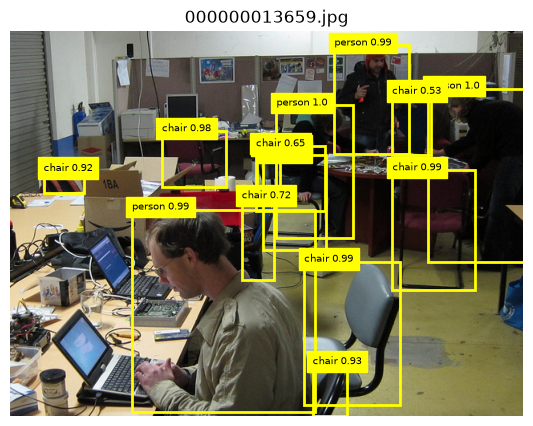

000000013659.jpg -> found: 4 person, 10 chair


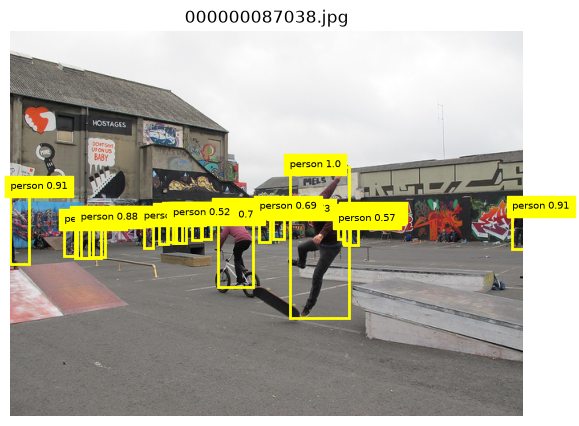

000000087038.jpg -> found: 20 person, 0 chair


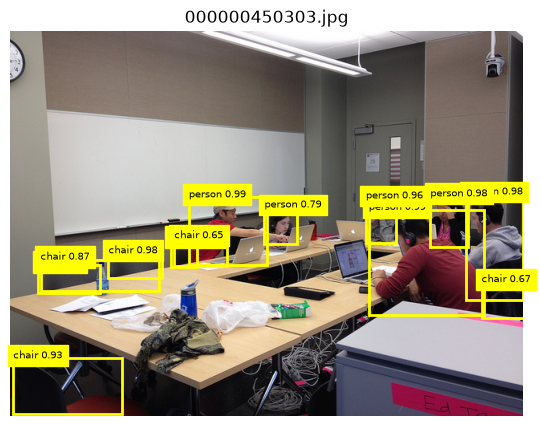

000000450303.jpg -> found: 6 person, 7 chair


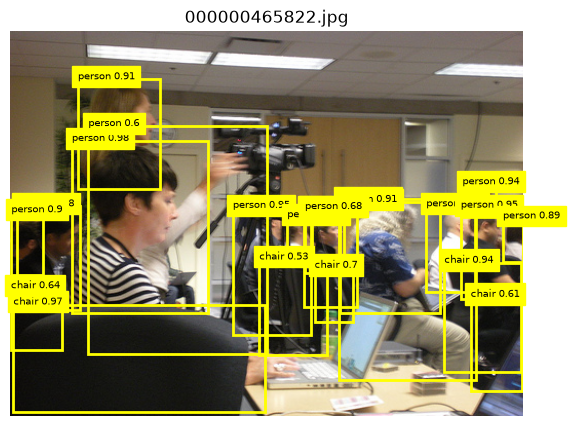

000000465822.jpg -> found: 15 person, 6 chair


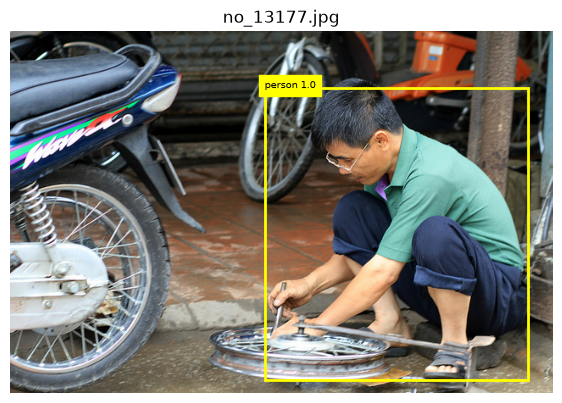

no_13177.jpg -> found: 1 person, 0 chair


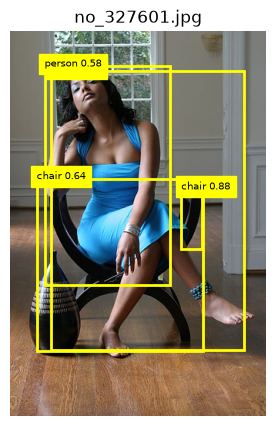

no_327601.jpg -> found: 2 person, 2 chair


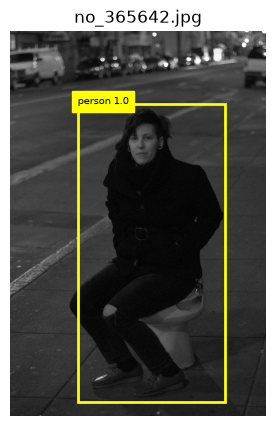

no_365642.jpg -> found: 1 person, 0 chair


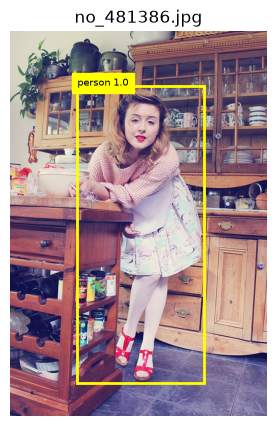

no_481386.jpg -> found: 1 person, 0 chair


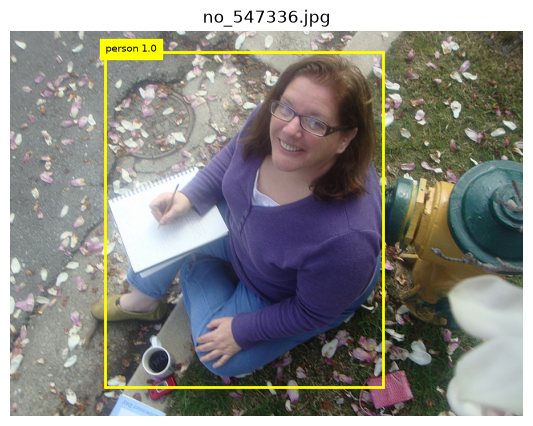

no_547336.jpg -> found: 1 person, 0 chair


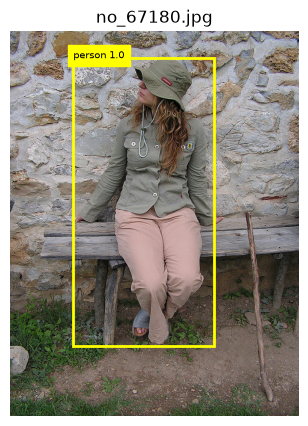

no_67180.jpg -> found: 1 person, 0 chair


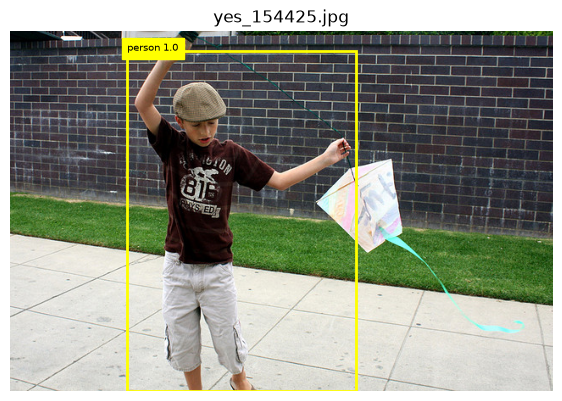

yes_154425.jpg -> found: 1 person, 0 chair


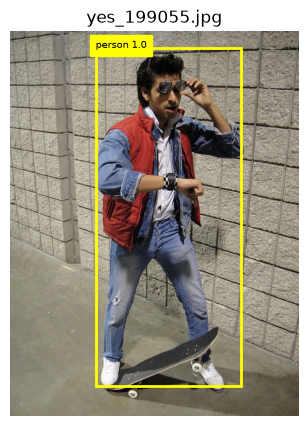

yes_199055.jpg -> found: 1 person, 0 chair


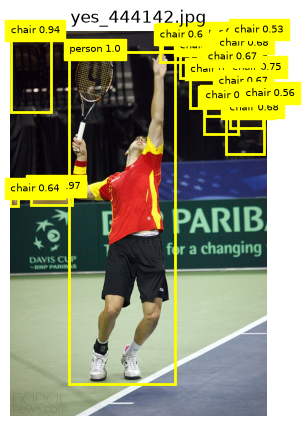

yes_444142.jpg -> found: 1 person, 18 chair


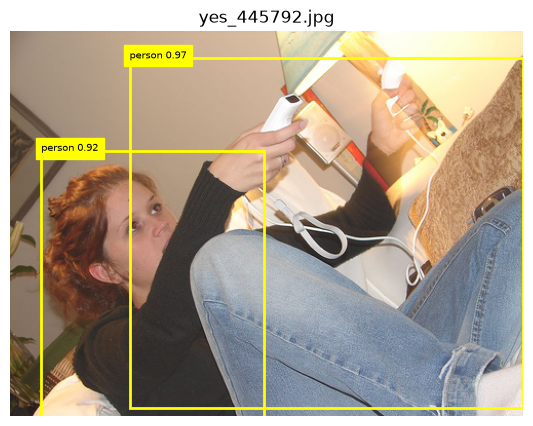

yes_445792.jpg -> found: 2 person, 0 chair


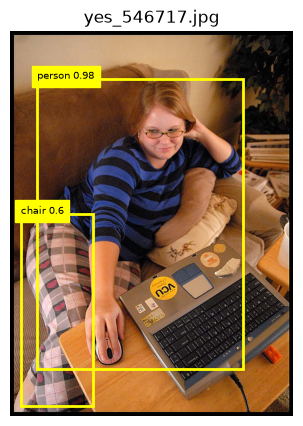

yes_546717.jpg -> found: 1 person, 1 chair


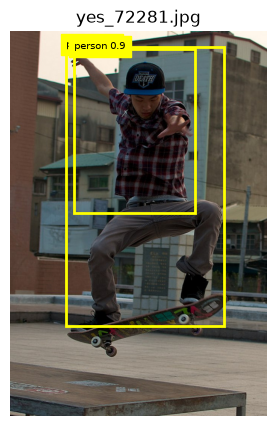

yes_72281.jpg -> found: 2 person, 0 chair


In [ ]:
threshold = 0.5

def my_app(picture, name=""):
    boxes = find(picture, what, threshold, model=model, title=name)
    c = counts(boxes, what)
    # Change this sentence so it answers YOUR question
 return "The study area has " + str(c["chair"]) + " chairs and " + str(c["person"]) + " people detected."

for name in photos:
    answer = my_app(photos[name], name)
    plt.show()
    print(name, "->", answer)

## 6. Ground truth

Count the objects in every photo **yourself** - before you trust the model -
and write it in `truth`. Agree first on what counts (half outside the photo?
hidden behind something?).

Then look at the model's boxes from section 5 and count, per photo, how many
of its boxes were **right** (a box on a real object of that kind). Write that
in `correct`. Use the exact file names.

In [9]:
truth = {      # how many there really are - counted by you (these are for the example photos)
    "000000087038.jpg": {"person": 13, "chair": 0},
    "000000450303.jpg": {"person": 6, "chair": 9},
    "000000465822.jpg": {"person": 12, "chair": 8},
    "000000013659.jpg": {"person": 5, "chair": 7},
}
correct = {    # how many of the model's boxes were right, at your threshold - judged by you
    "000000087038.jpg": {"person": 13, "chair": 0},
    "000000450303.jpg": {"person": 6, "chair": 4},
    "000000465822.jpg": {"person": 11, "chair": 3},
    "000000013659.jpg": {"person": 4, "chair": 6},
}

## 7. Evaluate

Three numbers per kind of object:

- **Precision** = right boxes / all boxes the model drew - *how many false alarms?*
- **Recall** = right boxes / objects that are really there - *how many missed?*
- **Count error** = on average, how many off per photo - *what the user notices*

The second cell tries other thresholds: which one gives the smallest count
error?

In [14]:
# Run, do not read
found = {}
for name in truth:
    found[name] = find(photos[name], what, 0.0, model=model, draw=False)   # every box, any confidence

def evaluate(threshold, verbose=True):
    total = {}
    for w in what:
        drawn = sum(sum(1 for b in found[n] if b[0] == w and b[1] >= threshold) for n in truth)
        real = sum(truth[n][w] for n in truth)
        errors = [abs(sum(1 for b in found[n] if b[0] == w and b[1] >= threshold) - truth[n][w]) for n in truth]
        total[w] = float(np.mean(errors))
        if verbose:
            right = sum(correct[n][w] for n in truth)
            print(w.ljust(12), "boxes", drawn, " right", right, " really there", real,
                  " precision", round(right / drawn, 2) if drawn else "-",
                  " recall", round(right / real, 2) if real else "-",
                  " count error", round(total[w], 2))
    return total

print("At threshold", threshold, "(precision and recall use your judgements in 'correct'):")
evaluate(threshold);

At threshold 0.5 (precision and recall use your judgements in 'correct'):
person       boxes 45  right 34  really there 36  precision 0.76  recall 0.94  count error 2.75
chair        boxes 23  right 13  really there 24  precision 0.57  recall 0.54  count error 1.75


In [12]:
for t in [0.3, 0.5, 0.7, 0.9]:
    errors = evaluate(t, verbose=False)
    print("threshold", t, " count error per photo:", {w: round(e, 2) for w, e in errors.items()})

threshold 0.3  count error per photo: {'person': 4.0, 'chair': 1.25}
threshold 0.5  count error per photo: {'person': 2.75, 'chair': 1.75}
threshold 0.7  count error per photo: {'person': 1.25, 'chair': 2.5}
threshold 0.9  count error per photo: {'person': 1.75, 'chair': 3.25}


**Questions for your presentation:** Which threshold is best for your app,
and which mistake does it make more: false alarms or misses? Which photos went
wrong, and why (light, distance, hidden, look-alikes)? Is the app good enough
for your user?

### Your evaluation conclusions

### Your evaluation conclusions

I tested my object recognition app on four example photos using different confidence thresholds.

At a threshold of 0.5, the model achieved a precision of 0.76 and a recall of 0.94 for people. For chairs, the precision was 0.57 and the recall was 0.54.

The best threshold for detecting people was **0.7**, with an average counting error of 1.25 people per photo.

For chairs, the best threshold was **0.3**, with an average counting error of 1.25 chairs per photo.

The model was better at detecting people than chairs. It sometimes detected objects incorrectly or missed objects, especially chairs that were partly hidden.

I think the app is useful as a basic demonstration, but it is not accurate enough to reliably count available seats. More testing with different photos could improve the evaluation.

## 8. End result and presentation checklist

Make the pictures for your slides with `save_result("name.png")` (in the same
cell as the picture) and download them all with `download_results()`.

| Part of your presentation | Where in this notebook | Done? |
|---------------------------|------------------------|-------|
| 1. What is the technique? input, output, what is it for | section 1 | |
| 2. Which data processing is needed? photo -> model, and the ground truth | sections 4 and 6 | |
| 3. What did you do? your idea, your photos, how you built your MVP | sections 3 and 5 | |
| 4. How do you evaluate it? metric, why, your result | section 7 | |
| 5. The end result: your MVP working, and where it fails | section 8 | |
| Extra: which photo is your best example, and which your worst? | below | |

Also prepare an answer to: **who could this app fail, and who could be harmed
by it?** The class will ask.

found: 4 person, 10 chair
saved results/best.png


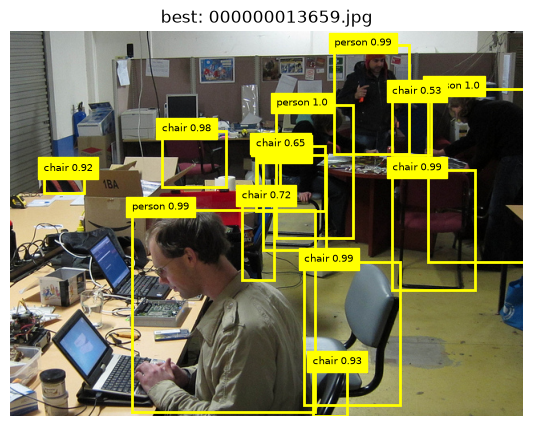

found: 6 person, 7 chair
saved results/worst.png


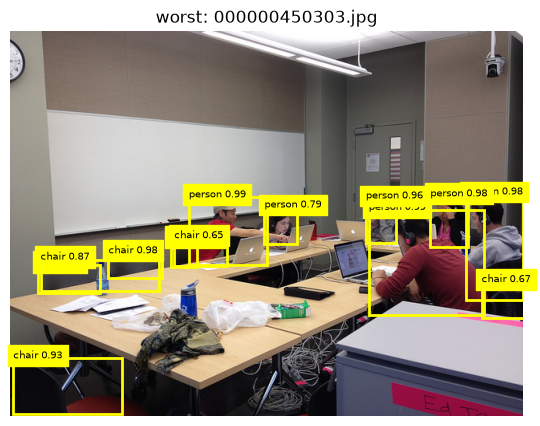

In [13]:
# The end result: your app on your best and your worst photo - saved for the slides
best, worst = list(photos)[0], list(photos)[2]      # change these to your own best and worst photo
for name, label in [(best, "best"), (worst, "worst")]:
    print(my_app(photos[name], label + ": " + name))
    save_result(label + ".png")
    plt.show()
# download_results()